In [1]:
import scipy as sp
from scipy.special import jv, hankel2, yv, spherical_jn, spherical_yn
import numpy as np
import matplotlib.pyplot as plt
from numpy import sqrt, linspace, zeros, ones, argmin, log, unravel_index
from utils import e_r_cpa_numerator, e_r_cpa, h_r_cpa, hl2, hl2prime, hl1, hl1prime
from scipy.special import jv, hankel2, yv, spherical_jn, spherical_yn
from numpy import sqrt, heaviside, pi

## The function `polarizability_denom`, defined below, gives the denominator of the dipolar polarizability (which should go to zero at the dipolar resonance) (see **Equation 9** of the Supplementary Information of the following paper: [A generalized non-local optical response theory for plasmonic nanostructures](https://static-content.springer.com/esm/art%3A10.1038%2Fncomms4809/MediaObjects/41467_2014_BFncomms4809_MOESM289_ESM.pdf)). 

## In the below, we need some expression for the diffusion constant. The literature is quite murky about this. In the below, we use $D\approx v_F^2/\omega_p$ (see discussion on **Page 30** of the following thesis: [From Classical to Quantum Plasmonics in Three and Two Dimensions](https://backend.orbit.dtu.dk/ws/portalfiles/portal/129469281/Christensen_PhDThesis.pdf))

In [2]:
def polarizability_denom(x, omega, gamma=1e-2, v_F=1e-3):
    # x = R*omega/c, where R is the radius, c is the speed of light
    # v_F is the Fermi velocity in units of the speed of light 
    # gamma is the bulk scattering rate, given in units of the plasma frequency
    # omega is the frequency given in units of the plasma frequency
    epsilon = 1 - 1/(omega**2+1j*omega*gamma) # Drude dielectric funtion 
                                              # (corresponding to the permittivity of the sphere 
                                              # for epsilon_infinity = 1
    beta = sqrt(3/5)*v_F # Corresponds to pressure forces
    omega_p = 1 # Plasma frequency in the units of the plasma frequency lol...
    D = (v_F**2)/omega_p # Diffusion constant
    
    eta_sqrd = beta**2 + D*gamma - 1j*D*omega
    knl_sqrd = (epsilon/(1-epsilon))*(1/eta_sqrd)*(1/omega**2)  
    knl = sqrt(knl_sqrd) # k_nl * R will be given by k_nl * x 

    z = x * knl # longitudinal mode
    delta = (epsilon-1)*(spherical_jn(1, z)/(z*spherical_jn(1, z, derivative=True)))
    return epsilon + 2*(1+delta)

## We now sweep over a range of radii in the nanometer range and find the resonance frequencies. We then fit with **Equation 7** and **Equation 8** of the following paper: [A generalized non-local optical response theory for plasmonic nanostructures](https://www.nature.com/articles/ncomms4809#MOESM289). Note that I believe **Equation 8** of this paper is off by a factor of two, which we correct below. 

In [3]:
N_Rs = 200 # Number of radii for which we find the resonance frequencies
N_omegas = 500 # Number of frequency points sampled 
Rs = linspace(1, 15, N_Rs) # Radii in nanometers
hbar_omega_p = 10 # hbar multiplied by the plasma frequency (in eV)
hbar_c = 200 # hbar multiplied by the speed of light in eV*nm

omegas_real = linspace(0.575, 0.59, N_omegas) # In units of omega_p
omegas_imag = linspace(0.004, 0.015, N_omegas) # In units of omega_p
omegas = omegas_real.reshape((N_omegas, 1)).repeat(N_omegas, axis=1) - 1j*omegas_imag.reshape((1, N_omegas)).repeat(N_omegas, axis=0)

best_omega_reals = []
best_omega_imags = []

for R in Rs:
    polarizability_map = polarizability_denom(R*omegas*hbar_omega_p/hbar_c, omegas)
    best_omega = omegas.flatten()[np.abs(polarizability_map).argmin()].item()
    best_omega_reals.append(best_omega.real)
    best_omega_imags.append(best_omega.imag)

In [9]:
v_F = 1e-3
beta = sqrt(3/5)*v_F
gamma = 1e-2
omega_p = 1
D = (v_F**2)/omega_p # Diffusion constant

best_omega_reals_approx = 1/sqrt(3) + (beta*hbar_c)/(sqrt(2)*Rs*hbar_omega_p)
best_omega_imags_approx = -gamma/2 - (sqrt(6)/12)*(D)*hbar_c/(beta*Rs*hbar_omega_p)

## We first plot the blue shift of the resonance frequency below: 

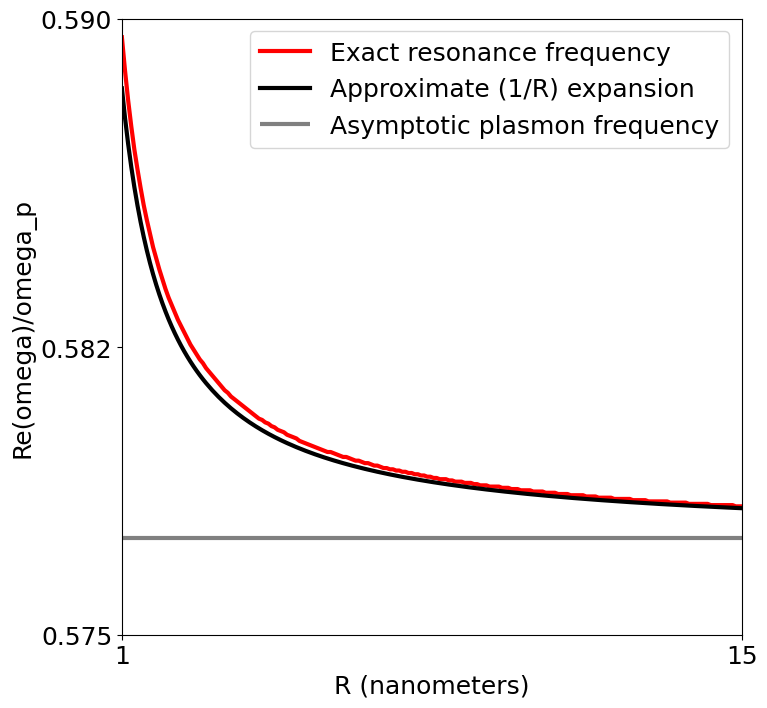

In [10]:
plt.rcParams.update({'font.size': 18})
fig, ax = plt.subplots(figsize=(8, 8))
ax.plot(Rs, best_omega_reals, color="red", label="Exact resonance frequency", linewidth=3)
ax.plot(Rs, best_omega_reals_approx, color="black", linewidth=3, label="Approximate (1/R) expansion")
ax.hlines([1/sqrt(3)], Rs.min(), Rs.max(), color="Grey", linewidth=3, label="Asymptotic plasmon frequency");
ax.set_ylim(omegas_real.min(), omegas_real.max());
ax.set_xlim(Rs.min(), Rs.max());
ax.set_xlabel("R (nanometers)")
ax.set_ylabel("Re(omega)/omega_p");
ax.set_xticks([Rs.min(), Rs.max()])
ax.legend();
ax.set_yticks([omegas_real.min().round(3), ((omegas_real.min()+omegas_real.max())/2).round(3), omegas_real.max().round(3)]);

## Now we plot the surface enhanced Landau damping rate (corresponding to the Kreibig parameter for the sphere).

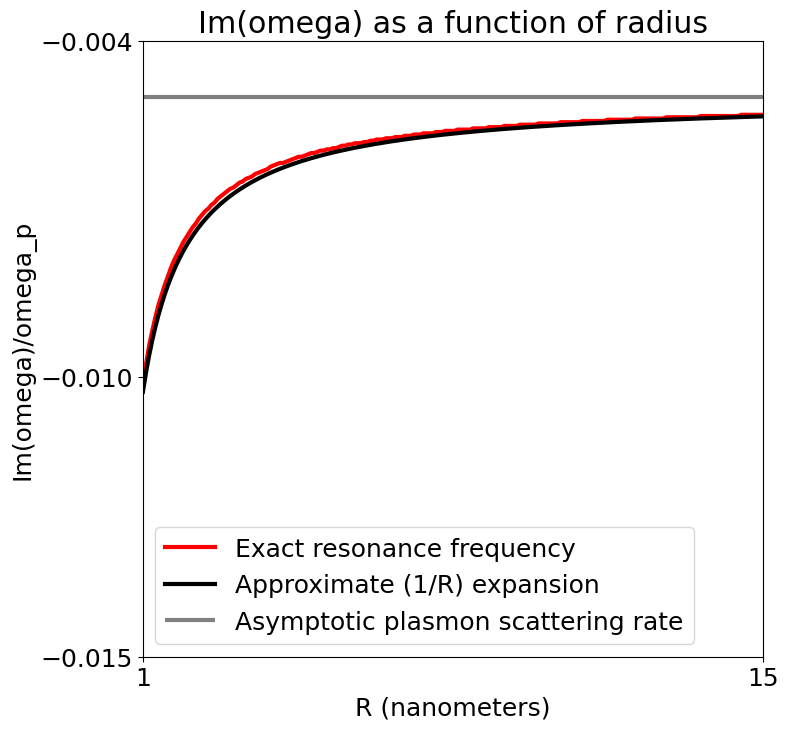

In [12]:
plt.rcParams.update({'font.size': 18})
fig, ax = plt.subplots(figsize=(8, 8))
ax.plot(Rs, best_omega_imags, color="red", label="Exact resonance frequency", linewidth=3)
ax.plot(Rs, best_omega_imags_approx, color="black", linewidth=3, label="Approximate (1/R) expansion")
ax.hlines([-gamma/2], Rs.min(), Rs.max(), color="Grey", linewidth=3, label="Asymptotic plasmon scattering rate");
ax.set_ylim(-omegas_imag.max(), -omegas_imag.min());
ax.set_xlim(Rs.min(), Rs.max());
ax.set_xlabel("R (nanometers)")
ax.set_ylabel("Im(omega)/omega_p");
ax.set_xticks([Rs.min(), Rs.max()])
ax.legend();
ax.set_yticks([-omegas_imag.min().round(3), -((omegas_imag.min()+omegas_imag.max())/2).round(3), -omegas_imag.max().round(3)]);
ax.set_title("Im(omega) as a function of radius");

## We now analytically motivate the expansions above. Using the notation of **Equation 9** of [A generalized non-local optical response theory for plasmonic nanostructures](https://static-content.springer.com/esm/art%3A10.1038%2Fncomms4809/MediaObjects/41467_2014_BFncomms4809_MOESM289_ESM.pdf), we know that the dispersion is given by $\varepsilon(\omega)+2(1+\delta_{nl})=0$, where $\delta_{nl}=-\frac{\omega_p^2}{\omega(\omega+i\gamma)}\frac{j_1(k_{nl}R)}{(k_{nl}R)j_1'(k_{nl}R)}$. We first note that $k_{nl}^2\approx -\frac{(2/3)\omega_p^2}{\beta^2-iD\omega_p/\sqrt{3}}\rightarrow k_{nl}\approx \Big[\frac{2}{3}\Big]^{1/2}\frac{i\omega_p}{\beta-iD\omega_p/(2\sqrt{3}\beta)}$. Note that $\Im(k_{nl}R)\gg 1$, thus we may write $\frac{j_1(k_{nl}R)}{(k_{nl}R)j_1'(k_{nl}R)}\approx \frac{i}{k_{nl}R}$. Thus, the dispersion relation is approximately given by the following: $\omega(\omega+i\gamma)-\omega_p^2+2(\omega(\omega+i\gamma)-i\omega_p^2/(k_{nl}R))=3\omega(\omega+i\gamma)-\omega_p^2\Big[1+\frac{2i}{k_{nl}R} \Big]=0$. Using our expression for $k_{nl}$ then gives us the following: 
## $3\omega(\omega+i\gamma)-\omega_p^2\Big[1+\frac{2}{\omega_p R}\Big[\frac{3}{2} \Big]^{1/2}\Big[\beta-iD\omega_p/(2\sqrt{3}\beta) \Big] \Big]$
## $\rightarrow \omega\approx \frac{\omega_p}{\sqrt{3}}-\frac{i\gamma}{2}+\frac{1}{R\sqrt{2}}\Bigg[\beta-\frac{iD\omega_p}{(2\sqrt{3}\beta)} \Bigg]$

## Note that this is precisely the approximation we used. 

# As a further sanity check, we try to re-produce **Figure 2b** of the following paper: [Blueshift of the surface plasmon resonance in silver nanoparticles: substrate effects](https://opg.optica.org/oe/fulltext.cfm?uri=oe-21-22-27344). Note that this figure does not include diffusion, but it still a useful sanity check. 

In [70]:
hbar_c = 200 # hbar multiplied by the speed of light in eV*nm
hbar_omega_p = 10 # Plasma frequency of silver (in eV). Note that the paper does not 
# give a value for this, so I had to play around with the value to make the plots below
# look reasonable. 

R_v = [2, 4, 8] # Radius in nanometers (corresponding to values chosen in Figure 2b)
beta = 5e-3 # In units of the speed of light
gamma = 0.05 # In units of the plasma frequency
omegas = linspace(0.4, 1.6, 1000) # frequencies we consider, in units of the plasma frequency

epsilon = 1 - 1/(omegas**2+1j*omegas*gamma) # Drude dielectric funtion 
knl_sqrd = (epsilon/(1-epsilon))*(1/beta**2)*(1/omegas**2)  
knl = sqrt(knl_sqrd) # k_nl*R will be given by k_nl * x 

deltas_v = []
for R in R_v:
    xs = R*omegas*hbar_omega_p/hbar_c
    zs = xs*knl # longitudinal mode
    deltas = (epsilon-1)*(spherical_jn(1, zs)/(zs*spherical_jn(1, zs, derivative=True)))
    deltas_v.append(deltas)

## Below is **Figure 2b** (approximately). Note that the paper does not indicate what value they used for the plasma frequency, but I played around with the value to find the best fit. 

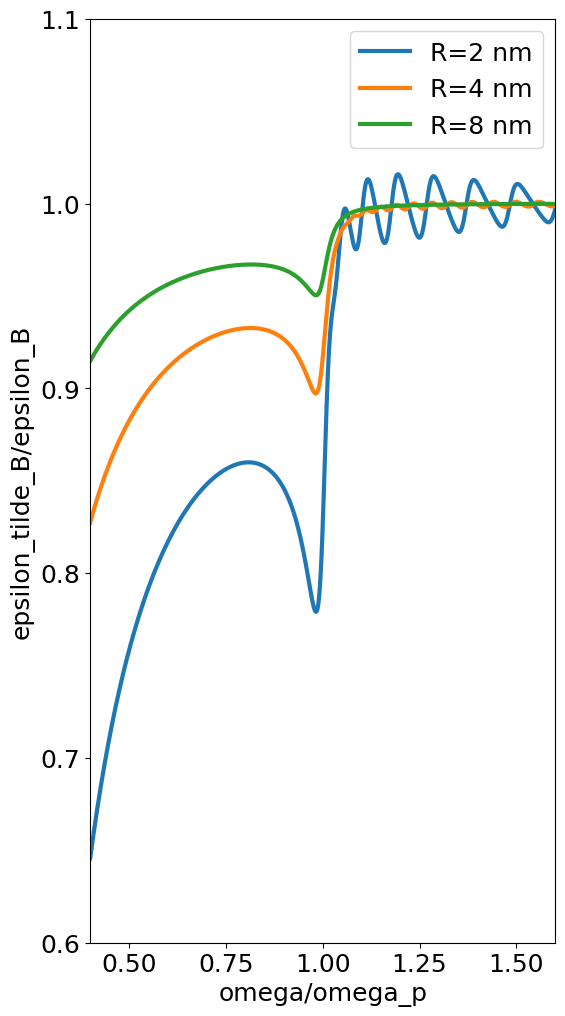

In [81]:
plt.rcParams.update({'font.size': 18})
fig, ax = plt.subplots(figsize=(6, 12))
for (R, deltas) in zip(R_v, deltas_v):
    ax.plot(omegas, 1 + deltas.real, linewidth=3, label=f"R={R} nm")
ax.set_xlim(omegas.min(), omegas.max())
ax.set_ylim(0.6, 1.1)
ax.legend();
ax.set_xlabel("omega/omega_p")
ax.set_ylabel("epsilon_tilde_B/epsilon_B");

## Now we move on to the case of a nanoshell (nonlocality only in the shell). To set the stage, and for maximal clarity, we derive the salient equations of motion below: 

## $\mathbf{E}(\mathbf{r}, t)=-\nabla\phi(\mathbf{r}, t) \rightarrow 0=\nabla\cdot(\nabla\times\mathbf{H}(\mathbf{r}, t))=-i\omega\varepsilon_0\varepsilon_\infty \nabla\cdot\mathbf{E}(\mathbf{r}, t)+\nabla\cdot \mathbf{J}(\mathbf{r}, t)$
## $\rightarrow \nabla^2\phi = en(\mathbf{r}, t)/(\varepsilon_0\varepsilon_\infty)$ (where $n(\mathbf{r}, t)$ is the number density)

## $\frac{\beta^2}{\omega(\omega+i\gamma)}\nabla(\nabla\cdot \mathbf{J}(\mathbf{r}, t))+\mathbf{J}(\mathbf{r}, t)=\sigma(\omega)\mathbf{E}(\mathbf{r}, t)$

## $\rightarrow -\frac{ie\beta^2}{\omega+i\gamma}\nabla n(\mathbf{r}, t)+\mathbf{J}(\mathbf{r}, t)=\sigma(\omega)\mathbf{E}(\mathbf{r}, t)$

## $\rightarrow \Psi(\mathbf{r}, t)=\frac{1}{i\omega-\gamma}\Big[(\varepsilon_0\omega_p^2)\phi(\mathbf{r}, t)-(e\beta^2)n(\mathbf{r}, t)\Big]$